In [1]:
import matplotlib.pyplot as plt
import numpy as np
from dataclasses import replace
from IPython.display import clear_output
from astropy.table import Table

import run_config
import utils_lya_halo

from run_config import cfg, smoke
from utils_lya_halo import (core, extract, PipelineConfig, run_extract, run_stack, 
read_galaxy_fits, measure, plotting, analysis, multicat)
from utils_lya_halo.io import read_galaxy_fits, apply_finite_cut
from utils_lya_halo.measure import measure_all_bins, integrated_line_flux
from utils_lya_halo.stack import build_stacks

%matplotlib inline

In [2]:
catalog_path="catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits"
catalog_path_old="catalogs/lya_halo_catalog_cuts/ALL_haoiii_sn5_mosdef_catalog.txt"

catalog = Table.read(catalog_path, format='fits')
catalog[:5]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

In [34]:
field = 'EGS'
# mask_override_ids = (1940, 4058, 6500, 13673, 14627, 15446, 15871, 17632, 
#                      25062, 26009, 30032, 32124, 36741, 37664, 38767, 40738,
#                      6283, 6889, 6803, 4837, 22044, 4065, 4081, 5814, 
#                      5252, 3121, 4441, 6018, 10567, 19642, 3284, 3117, 
#                      10066, 11961, 18907, 15673, 16115, 4019, 19717, 
#                      22193, 4196, 12780, 19098, 2335, 1299, 24582, 2665, 
#                      1823, 25094, 25197, 26043, 24813, 18569, 23886,
#                      12251, 21323, 23910)
# mask_override_ids_egs = (1940, 4058, 6500, 13673, 14627, 15446, 15871, 17632, 
#                          25062, 26009, 30032, 32124, 36741, 37664, 38767, 40738)
# mask_override_ids_cosmos = (6283, 6889, 6803, 4837, 22044, 4065, 4081, 5814, 
#                             5252, 3121, 4441, 6018, 10567, 19642, 3284, 3117, 
#                             10066, 11961, 18907, 15673, 16115, 4019, 19717, 
#                             22193, 4196, 12780, 19098, 2335, 1299, 24582, 2665, 
#                             1823, 25094, 25197, 26043, 24813, 18569, 23886,
#                             12251, 21323, 23910)

cfg2 = replace(cfg,
        catalog="MOSDEF",
        field=field,
        bin_mode='kpc',
        flux_unit="L_kpc2",
        bins=[0, 10, 20, 50, 100, 200, 500, 1000, 2000],
        catalog_path="catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits",
        n_bootstrap=1000,
        cont_image_path='auto')

vdfi = extract.load_field(cfg2)
run_table = extract.build_run_table(cfg2)

# # "before" mask -- no galaxy protection, documents the problem
# bad_before = masking.continuum_image_mask(
#     cfg2.resolve_cont_image_path(), field, cfg2.mask_percentile,
#     vdfi["RA"], vdfi["DEC"])

Loaded AEGIS: 141 exposures, 34944 fibers, 1036 wavelength pixels


# Plotting the Field

In [35]:
plotting.list_exposures(vdfi)   # see what's available before picking a subset

AEGIS: 141 exposure(s) of 141 total
exposure n_fibers      ra_mean            dec_mean            ra_min             ra_max            dec_min            dec_max      
-------- -------- ------------------ ------------------ ------------------ ------------------ ------------------ ------------------
       0    34944 214.91506427111642 52.888703520699735    214.66357421875 215.16294860839844  52.74835205078125  53.02848434448242
       1    34944 214.91545625877032  52.88901301203193 214.66397094726562 215.16334533691406  52.74866485595703  53.02879333496094
       2    34944 214.91570460228692 52.888654159102245 214.66421508789062 215.16358947753906  52.74830627441406  53.02843475341797
       3    34944  214.9213692430175 52.877446866734125 214.66993713378906 215.16920471191406 52.737098693847656   53.0172233581543
       4    34944 214.92176107696562  52.87775637629704  214.6703338623047 215.16958618164062  52.73740768432617  53.01753616333008
       5    34944 214.92200941655224  52

exposure,n_fibers,ra_mean,dec_mean,ra_min,ra_max,dec_min,dec_max
int64,int64,float64,float64,float64,float64,float64,float64
0,34944,214.91506427111642,52.888703520699735,214.66357421875,215.16294860839844,52.74835205078125,53.02848434448242
1,34944,214.91545625877032,52.88901301203193,214.66397094726562,215.16334533691406,52.74866485595703,53.02879333496094
2,34944,214.91570460228692,52.888654159102245,214.66421508789062,215.16358947753906,52.74830627441406,53.02843475341797
3,34944,214.9213692430175,52.877446866734125,214.66993713378906,215.16920471191406,52.737098693847656,53.0172233581543
4,34944,214.92176107696562,52.87775637629704,214.6703338623047,215.16958618164062,52.73740768432617,53.01753616333008
5,34944,214.92200941655224,52.87739754214392,214.6705780029297,215.1698455810547,52.7370491027832,53.01717758178711
6,34944,214.91118725708552,52.889775979322394,214.65968322753906,215.15908813476562,52.749427795410156,53.0295524597168
7,34944,214.91157907313044,52.890085528075915,214.6600799560547,215.15948486328125,52.74973678588867,53.02986145019531
8,34944,214.9118276528823,52.88972670724104,214.6603240966797,215.15972900390625,52.7493782043457,53.029502868652344


In [36]:
exp = np.linspace(0, 26, 27) * 5
exp

array([  0.,   5.,  10.,  15.,  20.,  25.,  30.,  35.,  40.,  45.,  50.,
        55.,  60.,  65.,  70.,  75.,  80.,  85.,  90.,  95., 100., 105.,
       110., 115., 120., 125., 130.])

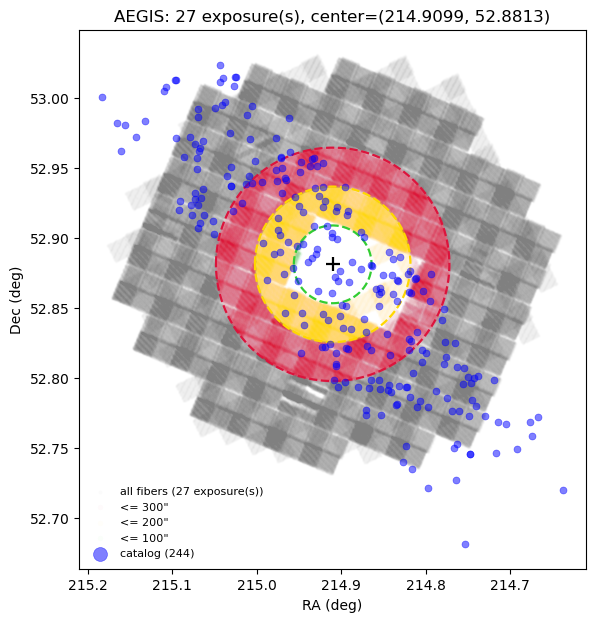

In [37]:
ax = plotting.plot_field_coverage(
    vdfi, run_table,
    exposures=exp,
    radii_arcsec=(100, 200, 300),
    fiber_size=2, fiber_alpha=0.02, background_alpha=0.03,
    catalog_kwargs={'s': 25, 'c':'blue', 'edgecolors': None, 'marker': None, 'alpha': 0.5},
    xc=None, yc=None,    # None -> auto-centers on the mosaic
)

# Testing Old Masking Method

In [5]:
# numerical overview
audit = core.audit_galaxy_mask_overlap(vdfi, run_table, bad_before, radius_arcsec=3.5)
audit[audit["flagged"]]   # which galaxies are affected, and by how much

audit_galaxy_mask_overlap: 30/244 galaxies have a masked fiber within 3.5"


index,n_bad_near,n_total_near,frac_bad_near,flagged
int64,int64,int64,float64,bool
15,236,236,1.0,True
25,126,247,0.5101214574898786,True
28,196,221,0.8868778280542986,True
29,17,255,0.06666666666666667,True
30,49,223,0.21973094170403587,True
37,8,41,0.1951219512195122,True
40,10,91,0.10989010989010989,True
41,45,251,0.17928286852589642,True
46,43,249,0.17269076305220885,True


(array([170.,   4.,   5.,   2.,   2.,   5.,   1.,   0.,   1.,   3.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

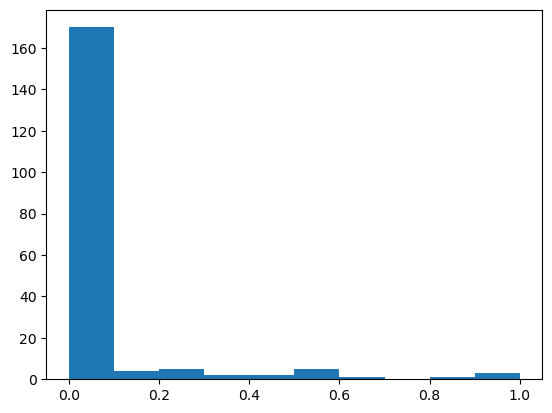

In [6]:
plt.hist(audit['frac_bad_near'], 10)

# Problem

audit_galaxy_mask_overlap: 65/278 galaxies have a masked fiber within 3.5"


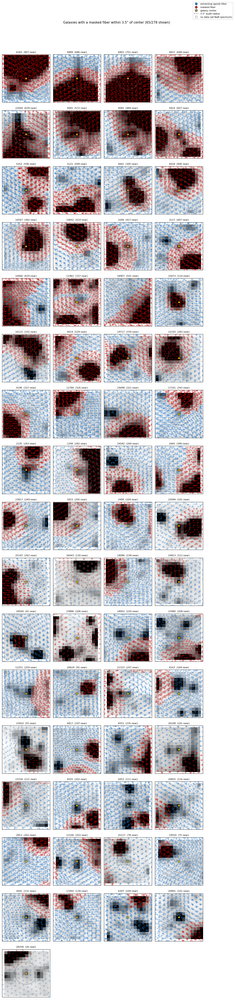

In [14]:
fig_before, _ = core.plot_fiber_mask_appendix(vdfi, run_table, bad_before, cfg2.resolve_cont_image_path(),
                                              radius_arcsec=3.5, cutout_arcsec=15.0,
                                              ncols=4, max_panels=None, panel_size=2.8,
                                              ra_col="RA", dec_col="DEC", id_col="ID",
                                              shared_scale=True, fiber_alpha=0.3, mark_dead_data=True)

# Testing the Core Spectrum Extraction Masking

In [18]:
if (field == 'COSMOS'):
    mask_field = mask_override_ids_cosmos
else:
    mask_field = mask_override_ids_egs

# 1. Compute once (slow part), don't plot yet
_, results = core.compare_mask_override_spectra(
    cfg2, galaxy_ids=list(mask_field),   # edge cases from the figure
    plot=False, radii=(0, 5))

Loaded COSMOS: 132 exposures, 34944 fibers, 1036 wavelength pixels
Same RA and bad_fiber_mask shape? True
Bad fibers: 610869
Good fibers: 4001739
Fraction bad: 0.132


extract_core:   0%|          | 0/41 [00:00<?, ?it/s]

Loaded COSMOS: 132 exposures, 34944 fibers, 1036 wavelength pixels
Same RA and bad_fiber_mask shape? True
Bad fibers: 602234
Good fibers: 4010374
Fraction bad: 0.131
Galaxy protection: 4372 px protected within 5" of 41 catalog galaxies


extract_core:   0%|          | 0/41 [00:00<?, ?it/s]




In [19]:
# 2. Plot / re-style freely -- as many times as you want, instantly
fig = core.plot_mask_override_spectra(
    results,
    ylim=(-0.5, 1),        # your adjustable y-limits (full panels)
    lya_zoom=True,       # right-hand inset zoomed on observed Lya
    zoom_hw_A=100,        # +/- window (observed A) of the zoom
    figsize_per_row=(10, 3),
)

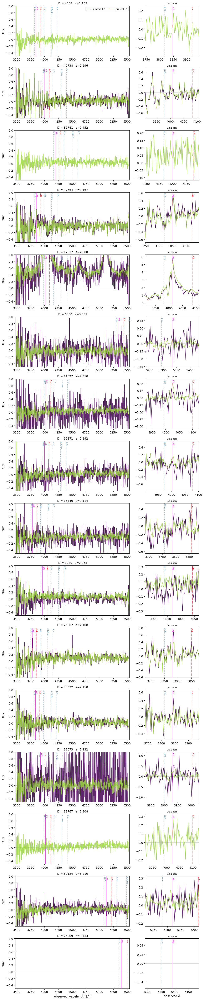

In [12]:
# 2. Plot / re-style freely -- as many times as you want, instantly
fig = core.plot_mask_override_spectra(
    results,
    ylim=(-0.5, 1),        # your adjustable y-limits (full panels)
    lya_zoom=True,       # right-hand inset zoomed on observed Lya
    zoom_hw_A=100,        # +/- window (observed A) of the zoom
    figsize_per_row=(10, 3),
)

In [9]:
catalog[catalog['ID'] == 1940]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

In [ ]:
vdfi = extract.load_field(cfg2)   # reuse if already loaded
core.diagnose_core_fibers(cfg2, galaxy_ids=[4058, 26009], vdfi=vdfi)